# Tiempo hasta una segunda compra: evaluación reservada

Consulta la [metodología](../docs/metodologia.md) y ejecuta las etapas en orden. Los comentarios se calculan con los resultados guardados.

In [1]:
from pathlib import Path
import sys
here = Path.cwd().resolve()
def _buscar_proyecto(paquete):
    """Encuentra el paquete propio desde el proyecto, tema o portafolio."""
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "src" / paquete).is_dir():
            return base
        for container in (base, base / "Analisis"):
            for pattern in (f"*/src/{paquete}", f"*/*/src/{paquete}"):
                for source in sorted(container.glob(pattern)):
                    parts = source.relative_to(container).parts
                    if "back" in parts or any(p.startswith(".") for p in parts):
                        continue
                    candidate = source.parent.parent
                    if (candidate / "pyproject.toml").is_file():
                        return candidate
    return None

PROJECT_ROOT = _buscar_proyecto("customer_return_survival")
if PROJECT_ROOT is None:
    raise RuntimeError("Abre este notebook desde su proyecto independiente.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from customer_return_survival.alerts import configurar_notebook, mostrar_alertas
from IPython.display import display, Markdown, Image
configurar_notebook()


# Tiempo hasta una segunda compra: evaluacion

C-index de test **0.562**, IC bootstrap 95 % **[0.529, 0.594]**: supera la referencia de ranking constante 0,5. Se usan **868 clientes** y **386 eventos**. Bootstrap con modelo fijo; no incluye incertidumbre del ajuste o selección. Las curvas agregadas son un diagnóstico visual, no una prueba de calibración. El protocolo no acredita desempeño futuro, causalidad ni pérdida de clientes. La censura administrativa puede relacionarse con estacionalidad y fecha de entrada.


,Indicador,Valor
0,clientes_test,868
1,eventos_test,386
2,baseline_c_index,0.5
3,modelo_c_index,0.561871
4,ci_bootstrap95_inferior,0.528863
5,ci_bootstrap95_superior,0.593726
6,replicas_validas,200
7,diagnostico,Discriminación con censura; no mide calibració...


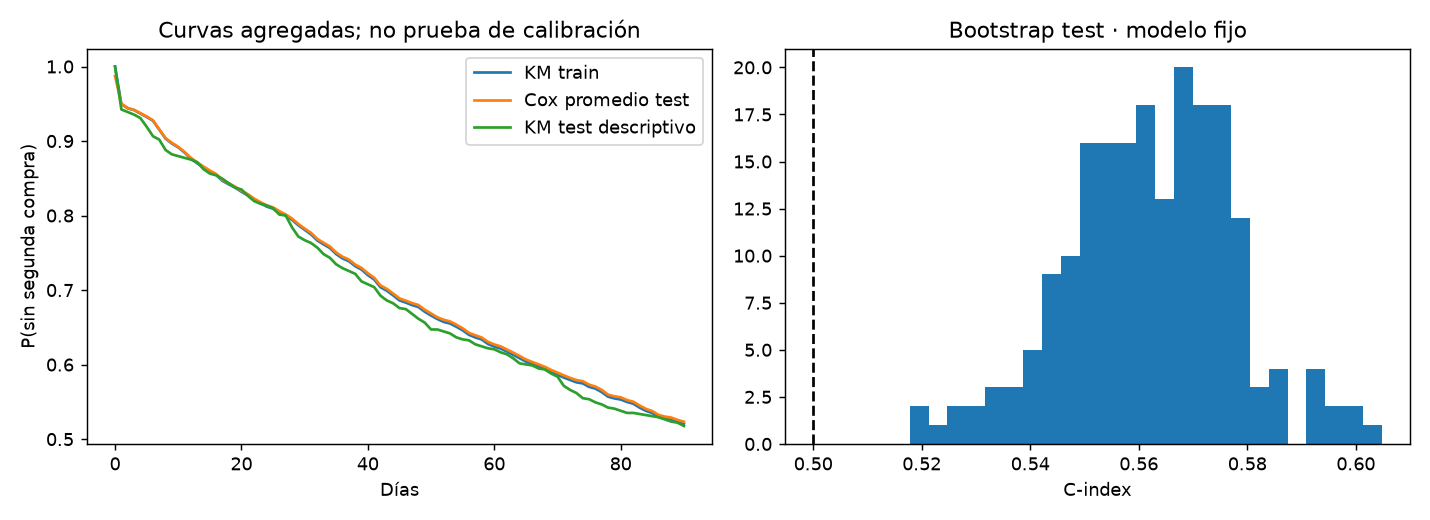

In [2]:
from customer_return_survival.analysis import run_stage
import pandas as pd
metrics,comment=run_stage(PROJECT_ROOT,"evaluacion")
display(Markdown(comment))
scalars={k:v for k,v in metrics.items() if not isinstance(v,(dict,list))}
if scalars:display(pd.DataFrame(list(scalars.items()),columns=["Indicador","Valor"]))
if "candidatos" in metrics:display(pd.DataFrame(metrics["candidatos"]))
for filename in ["eda.png","evaluacion.png"]:
    path=PROJECT_ROOT/"reports/evaluacion"/filename
    if path.exists():display(Image(filename=str(path)))
for filename in ["estimaciones.csv","metricas_test.csv","horas_por_empleado.csv", "estabilidad_semillas.csv", "centralidad.csv"]:
    path=PROJECT_ROOT/"reports/evaluacion"/filename
    if path.exists():display(pd.read_csv(path).head(20))

In [3]:
mostrar_alertas(PROJECT_ROOT / "reports/alertas/05_evaluacion.json")
from customer_return_survival.informe import generar_informe
generar_informe(PROJECT_ROOT)
display(Markdown("[Abrir informe integral](../reports/informe_final/informe_final.md)"))

[Abrir informe integral](../reports/informe_final/informe_final.md)